In [1]:
from pathlib import Path
from io import StringIO
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.colors as mcolors

files = ["PLA_ECO_VERS_1x5_2x5_3x5.csv", "PLA_ECO_VERS_4x5_5x5_6x5.csv", "PLA_ECO_VERS_7x5_8x5_9x5.csv", "PLA_ECO_VERS_9bx2.csv"]  
max_file_size = 19

all_dfs = []

for file in files:
    
    with open(file, "r") as f:
        lines = f.readlines()
        
    series_blocks = []
    current_block = []

    for line in lines:
        if line.strip().startswith(tuple(str(i) + ",Time" for i in range(1, max_file_size+1))):
            # save current block (if any)
            if current_block:
                series_blocks.append(current_block)
                current_block = []
        current_block.append(line)
        
    
    # add the last one
    if current_block:
        series_blocks.append(current_block)

    time_series_list = []
    max_length = []
    max_force = []
    
    file_size = len(series_blocks) - 1

    for block in series_blocks[1:]:
        # Find the series ID (first number before comma)
        header_line = block[0].strip()
        series_id = header_line.split(',')[0]

        # Skip the first 2 header lines (like "1,Time..." and ",(s),(mm),(kN)")
        data = ''.join(block[2:])

        # Use io.StringIO instead of pandas.compat.StringIO
        df = pd.read_csv(StringIO(data), header=None, names=["_", "Time", "Displacement", "Force"])
        df = df.drop(columns=["_"])  # drop empty index column
        df["Series"] = series_id
        time_series_list.append(df)
        max_length.append(df["Displacement"].max())
        max_force.append(df["Force"].max())
        
    start = None
    for i, line in enumerate(lines):
        if line.strip() == "Results Table 1":
            start = i + 3
            break
            
    table_lines = lines[(start) : (start + file_size)]
    header = lines[start-2].split(",")
    df = pd.read_csv(StringIO("".join(table_lines)), names = header)
    df["Elongation at break (%)"] = [elon * 100/60 for elon in max_length]
    df["Maximum force (kN)"] = [force for force in max_force]
    all_dfs.append(df)
        

final_df = pd.concat(all_dfs, ignore_index=True)

cols = [
    "Tensile stress at Yield (Offset 0.2 %)",
    "Modulus (Automatic Young's)",
    "Elongation at break (%)",
    "Maximum force (kN)"
]

final_df[cols] = final_df[cols].apply(pd.to_numeric, errors="coerce")

material = pd.read_csv("PLA_ECO_VERS_guide.csv")
final_df = pd.concat([final_df, material], axis = 1)

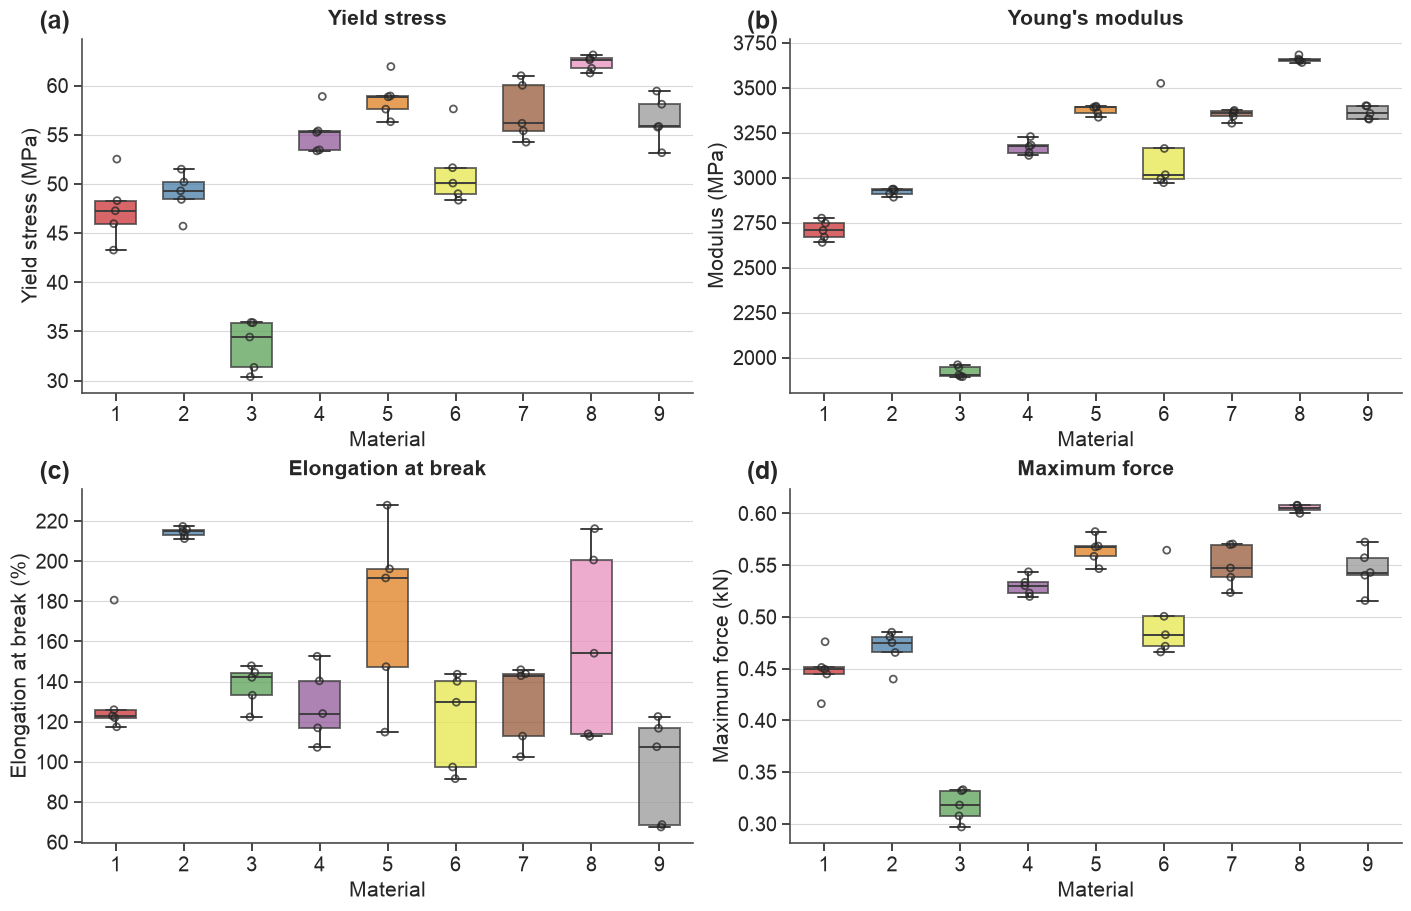

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ---- Global style ----
sns.set_theme(style="whitegrid", context="paper", font_scale=1.6)
plt.rcParams.update({
    "font.family": "Arial",      # or "Arial"/"Times New Roman" to match the journal
    "axes.edgecolor": "0.3",
    "axes.linewidth": 1.2,
    "grid.color": "0.85",
    "grid.linewidth": 0.8,
    "axes.titleweight": "bold",
    "pdf.fonttype": 42,                # editable text in PDF (journals prefer this)
})

# ---- Data prep: keep the original material order ----
order = list(dict.fromkeys(final_df["Material"]))
final_df["Material"] = pd.Categorical(final_df["Material"], categories=order, ordered=True)

palette = sns.color_palette("Set1", n_colors=len(order))

# ---- What to plot: (column, title, y-label) ----
panels = [
    ("Tensile stress at Yield (Offset 0.2 %)", "Yield stress",       "Yield stress (MPa)"),
    ("Modulus (Automatic Young's)",            "Young's modulus",    "Modulus (MPa)"),
    ("Elongation at break (%)",                "Elongation at break","Elongation at break (%)"),
    ("Maximum force (kN)",                     "Maximum force",      "Maximum force (kN)"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)

for i, (ax, (col, title, ylabel)) in enumerate(zip(axes.flat, panels)):
    sns.boxplot(
        data=final_df, x="Material", y=col, hue="Material", order=order,
        palette=palette, width=0.6, linewidth=1.4, fliersize=0,   # hide fliers, shown by stripplot
        boxprops={"alpha": 0.75}, legend=False, ax=ax,
    )
    sns.stripplot(
        data=final_df, x="Material", y=col, order=order,
        facecolor="none", edgecolor="0.15", linewidth=1.3,
        size=5, alpha=0.75, jitter=0.05, ax=ax,
    )
    ax.set_title(title, pad=10)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Material")

    ax.tick_params(axis="x", bottom=True, length=6, width=1.2, direction="out")
    ax.tick_params(axis="y", left=True, length=6, width=1.2, direction="out")

    ax.grid(axis="y", which="major", visible=True)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)
    ax.text(-0.02, 1.08, f"({'abcd'[i]})", transform=ax.transAxes,
            fontsize=18, fontweight="bold", va="top", ha="right")

fig.savefig("tensile_results.pdf", bbox_inches="tight")             # vector, for the paper
fig.savefig("tensile_results.png", dpi=300, bbox_inches="tight")    # raster backup
plt.show()

In [5]:
cols = [
    "Material",
    "Tensile stress at Yield (Offset 0.2 %)",
    "Modulus (Automatic Young's)",
    "Elongation at break (%)",
    "Maximum force (kN)",
]

export_df = export_df.rename(columns={
    "Material": "Formulation",
    "Tensile stress at Yield (Offset 0.2 %)": "Yield stress, 0.2% offset (MPa)",
    "Modulus (Automatic Young's)": "Young's modulus (MPa)",
    "Elongation at break (%)": "Elongation at break (%)",
    "Maximum force (kN)": "Maximum force (kN)",
})

export_df.to_csv("tensile_results.csv", index=False, encoding="utf-8-sig")